# PIMC - Proton in a double well potential

In [10]:
import numpy as np
import scipy.constants as const
from scipy.ndimage import uniform_filter1d
from dataclasses import dataclass

@dataclass
class SimulationParams:
    P: int
    N_sweep: int
    N: int
    C: float
    a: float
    m: float
    V0: float
    T: float
    omega_P: float
    dx: float

# Functions
def random_displacement(dx: float) -> float:
    """
    dx: Maximum displacement
    Generate a random displacement following dx*(eta-0.5), where eta is a uniform random number in [0, 1].
    """
    eta = np.random.uniform(0, 1)
    return dx * (2 * eta - 1)

def V(x: float, a: float, V0: float) -> float:
    """
    x: Position
    a: Potential length parameter
    V0: Potential energy parameter
    Potential energy function.
    """
    return V0 * ((x / a)**2 - 1)**2

def Delta_U(state: np.ndarray, bead_index: int, displacement: float, params: SimulationParams) -> float:
    """
    state: Current state of the system (positions of beads)
    bead_index: Index of the bead to be displaced
    displacement: Amount of displacement for the bead
    params: Simulation parameters
    Calculate the change in potential energy for a given bead index and displacement.
    """
    # Compute the diff in potential energy
    V_diff = (1/params.P) * (V(state[bead_index] + displacement, params.a, params.V0) - V(state[bead_index], params.a, params.V0))
    if params.P == 1:
        return V_diff  # No spring energy for a single bead

    # Compute the diff in spring energy
    xj_old = state[bead_index]
    xj_new = xj_old + displacement
    xjp = state[(bead_index + 1) % params.P]
    xjm = state[(bead_index - 1) % params.P]
    spring_diff = 0.5 * params.m * params.omega_P**2 * ((xjp - xj_new)**2 + (xj_new - xjm)**2 - (xjp - xj_old)**2 - (xj_old - xjm)**2)
    return V_diff + spring_diff

def metropolis_acceptance(delta_U: float, params: SimulationParams) -> bool:
    """
    delta_U: Change in energy
    params: Simulation parameters
    Metropolis acceptance criterion.
    """
    if delta_U < 0:
        return True
    else:
        acceptance_prob = np.exp(-delta_U / (const.k * params.T))
        return np.random.uniform(0, 1) <= acceptance_prob

def algo_step(
        M_conf: np.ndarray, 
        success_list: np.ndarray, 
        sum_x: np.ndarray,
        sum_V: np.ndarray,
        i: int, 
        params: SimulationParams,
        ) -> None:
    """
    M_conf: Configuration state of beads
    success_list: List to store success rates
    sum_x: List to store sum of beads positions
    sum_V: List to store sum of potential energies
    i: Current iteration index
    params: Simulation parameters
    Perform a single step of the Metropolis algorithm.
    """
    # Randomly select a bead index
    bead_index = np.random.randint(0, params.P)

    # Generate a random displacement
    displacement = random_displacement(params.dx)

    # Calculate the change in potential energy
    delta_U = Delta_U(M_conf, bead_index, displacement, params)

    # Decide whether to accept the move
    if metropolis_acceptance(delta_U, params):
        x_old = M_conf[bead_index]
        M_conf[bead_index] += displacement
        success_list[i] = 1  # Move accepted
        if i != 0:
            sum_x[i] = sum_x[i-1] + M_conf[bead_index] - x_old  # Update the sum of beads positions
            sum_V[i] = sum_V[i-1] + V(M_conf[bead_index], params.a, params.V0) - V(x_old, params.a, params.V0)  # Update the sum of potential energies
            return
    else:
        success_list[i] = 0  # Move rejected
        if i != 0:
            sum_x[i] = sum_x[i-1]  # Store the sum of beads positions
            sum_V[i] = sum_V[i-1]  # Store the sum of potential energies
            return
    sum_x[i] = np.sum(M_conf)  # Store the sum of beads positions
    sum_V[i] = np.sum([V(x, params.a, params.V0) for x in M_conf])  # Store the sum of potential energies
    return


def run_simulation(N_sweep: int = 1000, P: int = 50, C: float = 0.3, a_corr: float = 1.0, burn_in_sweeps: int = 0, T_factor: float = 0.4):
    """
    N_sweep: Number of sweeps
    P: Number of beads
    C: Unit reduction factor
    a_corr: Correction factor for tuning dx
    burn_in_sweeps: Initial sweeps excluded from the histograms (included in N_sweep).
    Run the Metropolis algorithm for N iterations and sample histograms once per production sweep.
    """
    if not 0 <= burn_in_sweeps < N_sweep:
        raise ValueError("burn_in_sweeps must be between 0 and N_sweep - 1")

    # Constants
    a = 0.04e-9 # Potential lenght parameter
    m = const.m_p # proton mass
    V0 = const.hbar**2 / (2 * m * a**2 * C) # Potential energy parameter
    T = T_factor * V0 / const.k # Simulation temperature
    omega_P = np.sqrt(P) * const.k * T / const.hbar # Quantum spring frequency
    P_ref = 50 # Reference number of beads for dx calculation
    dx_ref = 0.4 * a # Reference spatial step size
    dx = dx_ref * np.sqrt(P_ref / P) * a_corr # Adjusted spatial step size to maintain a similar acceptance rate (45%)
    N = N_sweep * P # Total number of iterations
    params = SimulationParams(
        P=P,
        N_sweep=N_sweep,
        N=N, 
        C=C, 
        a=a, 
        m=m, 
        V0=V0, 
        T=T, 
        omega_P=omega_P, 
        dx=dx,
        )

    # Initialization
    M_conf = a*np.ones(params.P) # Configuration state of beads
    success_list = np.zeros(N, dtype=int) # List to store success rates
    sum_x = np.zeros(N) # List to store sum of beads positions
    sum_V = np.zeros(N) # List to store sum of potential energies
    edges = np.linspace(-2.5, 2.5, 101) # Shared histogram edges in reduced position x/a
    bead_counts = np.zeros(len(edges) - 1, dtype=np.int64)
    centroid_counts = np.zeros_like(bead_counts)

    for i in range(int(N)):
        algo_step(
            M_conf, 
            success_list, 
            sum_x,
            sum_V,
            i, 
            params,
            )
        # Record every completed production sweep, including rejected moves.
        if (i + 1) % P == 0 and (i + 1) > burn_in_sweeps * P:
            bead_counts += np.histogram(M_conf / a, bins=edges)[0]
            centroid_counts += np.histogram([M_conf.mean() / a], bins=edges)[0]

    widths = np.diff(edges)
    rho = bead_counts / (bead_counts.sum() * widths)
    rho_centroid = centroid_counts / (centroid_counts.sum() * widths)

    return (M_conf, success_list, sum_x / params.P, sum_V / params.P, params, rho, rho_centroid, edges)

# Question 3: practical choices of displacement and run length
Run the function definitions above, then the cell below (a few seconds). The first figure compares displacements and selects the one nearest 45% acceptance as a starting choice. The second checks three independent runs with that displacement.

Choose a run length where all three running averages settle in their green bands and stay there for the remaining run. The bands are example accuracy goals: position within 0.05 a of zero, and potential energy within 5% of the classical reference. They are not confidence intervals. Also look for repeated visits to both wells and a histogram close to the reference curve. Increase `N_max` if needed; this cell is specifically for P=1 and kT/V0=0.4.


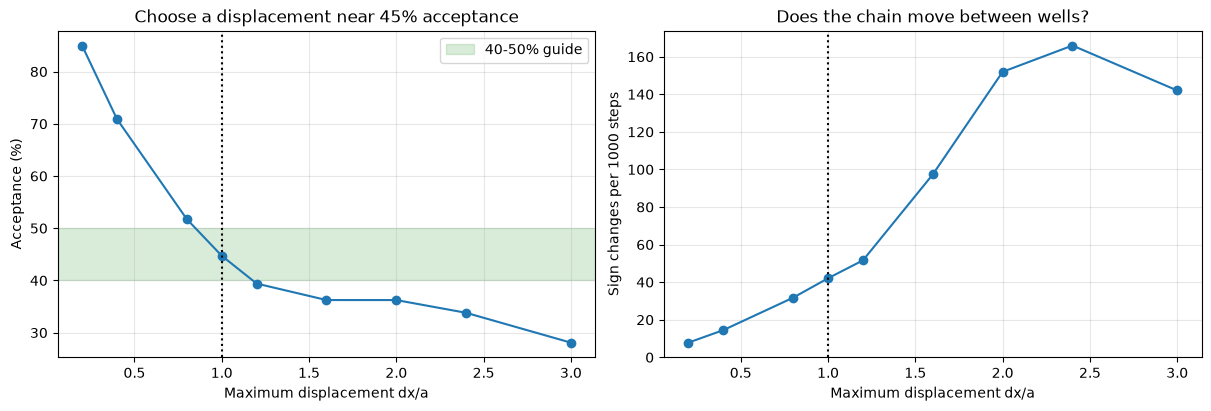

Practical starting choice: dx = 1.00 a (a_corr = 0.354, acceptance = 44.7%).
Seed 10: <x>/a = -0.0341, <V>/V0 = 0.2287, fraction in right well = 0.481
Seed 20: <x>/a = -0.0164, <V>/V0 = 0.2266, fraction in right well = 0.492
Seed 30: <x>/a = -0.0282, <V>/V0 = 0.2267, fraction in right well = 0.485


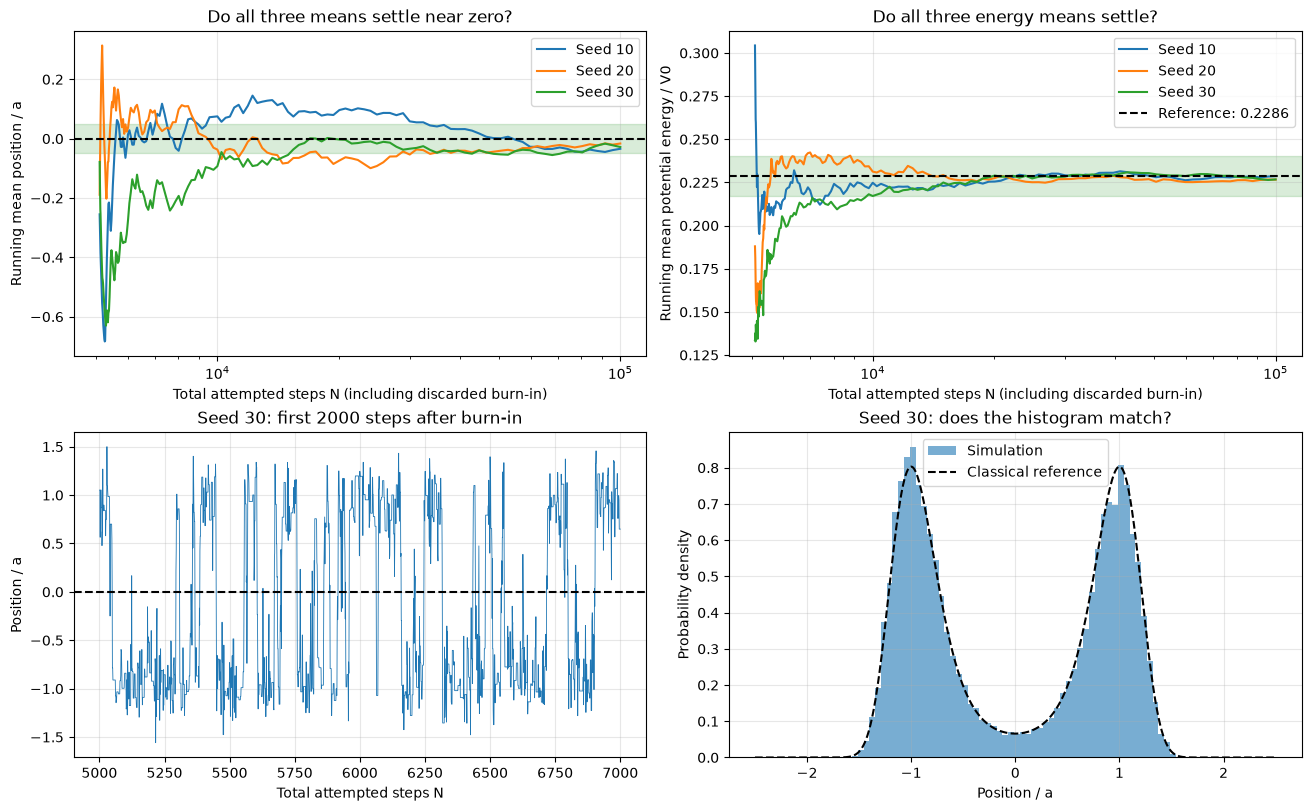

Choose N where ALL three running means enter the green bands and remain stable afterwards.
Also check repeated well visits and agreement with the reference histogram.
Green bands: position within 0.05 a of zero; energy within 5% of reference.
These are visual checks for a practical choice, not a proof of convergence.


In [2]:
# Question 3: a practical choice of dx and N for P = 1
# Run the cell defining run_simulation first. Adjust these settings if needed.
import matplotlib.pyplot as plt

dx_over_a = np.array([0.2, 0.4, 0.8, 1.0, 1.2, 1.6, 2.0, 2.4, 3.0])
N_pilot = 20_000
N_max = 100_000
burn_in = 5_000
seeds = [10, 20, 30]

# 1. Compare displacement sizes. For P=1, dx/a = 0.4*sqrt(50)*a_corr.
acceptance = []
crossings = []
for ratio in dx_over_a:
    np.random.seed(123)
    _, accepted, x, _, p, *_ = run_simulation(
        N_pilot, P=1, C=0.3, a_corr=ratio / (0.4 * np.sqrt(50))
    )
    x = x[burn_in:] / p.a
    acceptance.append(np.mean(accepted[burn_in:]))
    # A rough mixing check: sign changes can include quick recrossings.
    crossings.append(1000 * np.mean(np.sign(x[1:]) != np.sign(x[:-1])))

acceptance = np.array(acceptance)
best = np.argmin(np.abs(acceptance - 0.45))
chosen_dx = dx_over_a[best]
chosen_corr = chosen_dx / (0.4 * np.sqrt(50))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(dx_over_a, 100 * acceptance, 'o-')
axes[0].axhspan(40, 50, alpha=0.15, color='green', label='40-50% guide')
axes[0].set(xlabel='Maximum displacement dx/a', ylabel='Acceptance (%)',
            title='Choose a displacement near 45% acceptance')
axes[0].legend()
axes[1].plot(dx_over_a, crossings, 'o-')
axes[1].set(xlabel='Maximum displacement dx/a', ylabel='Sign changes per 1000 steps',
            title='Does the chain move between wells?')
for ax in axes:
    ax.axvline(chosen_dx, color='black', ls=':', label='Chosen dx')
    ax.grid(alpha=0.3)
plt.show()
print(f'Practical starting choice: dx = {chosen_dx:.2f} a '
      f'(a_corr = {chosen_corr:.3f}, acceptance = {100 * acceptance[best]:.1f}%).')

# 2. Keep dx fixed and check convergence with three independent random seeds.
# Exact classical reference at P=1: density proportional to exp(-V / kT).
y_grid = np.linspace(-2.5, 2.5, 2001)
potential = (y_grid**2 - 1)**2
density = np.exp(-potential / 0.4)
density /= np.trapezoid(density, y_grid)
V_reference = np.trapezoid(potential * density, y_grid)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for seed in seeds:
    np.random.seed(seed)
    _, _, x, energy, p, *_ = run_simulation(N_max, P=1, C=0.3, a_corr=chosen_corr)
    x_prod = x[burn_in:] / p.a
    V_prod = energy[burn_in:] / p.V0
    count = np.arange(1, len(x_prod) + 1)
    # Plot prefixes of one long run, rather than restarting for every N.
    indices = np.unique(np.geomspace(100, len(count), 150).astype(int)) - 1
    steps = burn_in + count[indices]
    axes[0, 0].plot(steps, (np.cumsum(x_prod) / count)[indices], label=f'Seed {seed}')
    axes[0, 1].plot(steps, (np.cumsum(V_prod) / count)[indices], label=f'Seed {seed}')
    print(f'Seed {seed}: <x>/a = {np.mean(x_prod):+.4f}, '
          f'<V>/V0 = {np.mean(V_prod):.4f}, '
          f'fraction in right well = {np.mean(x_prod > 0):.3f}')

# The shaded regions are example accuracy goals, not confidence intervals.
axes[0, 0].axhspan(-0.05, 0.05, color='green', alpha=0.15)
axes[0, 0].axhline(0, color='black', ls='--')
axes[0, 0].set(ylabel='Running mean position / a', title='Do all three means settle near zero?')
axes[0, 1].axhspan(0.95 * V_reference, 1.05 * V_reference, color='green', alpha=0.15)
axes[0, 1].axhline(V_reference, color='black', ls='--', label=f'Reference: {V_reference:.4f}')
axes[0, 1].set(ylabel='Running mean potential energy / V0', title='Do all three energy means settle?')
for ax in axes[0]:
    ax.set(xlabel='Total attempted steps N (including discarded burn-in)', xscale='log')
    ax.legend()

# Show the last seed's trajectory and distribution after burn-in.
trace_length = min(2000, len(x_prod))
axes[1, 0].plot(burn_in + count[:trace_length], x_prod[:trace_length], lw=0.6)
axes[1, 0].axhline(0, color='black', ls='--')
axes[1, 0].set(xlabel='Total attempted steps N', ylabel='Position / a',
               title=f'Seed {seeds[-1]}: first 2000 steps after burn-in')
axes[1, 1].hist(x_prod, bins=60, density=True, alpha=0.6, label='Simulation')
axes[1, 1].plot(y_grid, density, 'k--', label='Classical reference')
axes[1, 1].set(xlabel='Position / a', ylabel='Probability density',
               title=f'Seed {seeds[-1]}: does the histogram match?')
axes[1, 1].legend()
for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.show()
print('Choose N where ALL three running means enter the green bands and remain stable afterwards.')
print('Also check repeated well visits and agreement with the reference histogram.')
print('Green bands: position within 0.05 a of zero; energy within 5% of reference.')
print('These are visual checks for a practical choice, not a proof of convergence.')


# Question 5

### Simulation

In [11]:
# N_sweep includes the discarded equilibration sweeps.
q5_burn_in_sweeps = 5_000
np.random.seed(42)  # Change the seed to check reproducibility of the distributions.
M_conf, success_list, centroid_positions, mean_energies, params, rho, rho_centroid, edges = run_simulation(
    500_000, P=15, C=0.3, a_corr=1.0, burn_in_sweeps=q5_burn_in_sweeps, T_factor=0.6
)
print(f"Production sweeps recorded: {params.N_sweep - q5_burn_in_sweeps:,}")
print(f"Production acceptance: {100 * np.mean(success_list[q5_burn_in_sweeps * params.P:]):.1f}%")


Production sweeps recorded: 495,000
Production acceptance: 38.7%


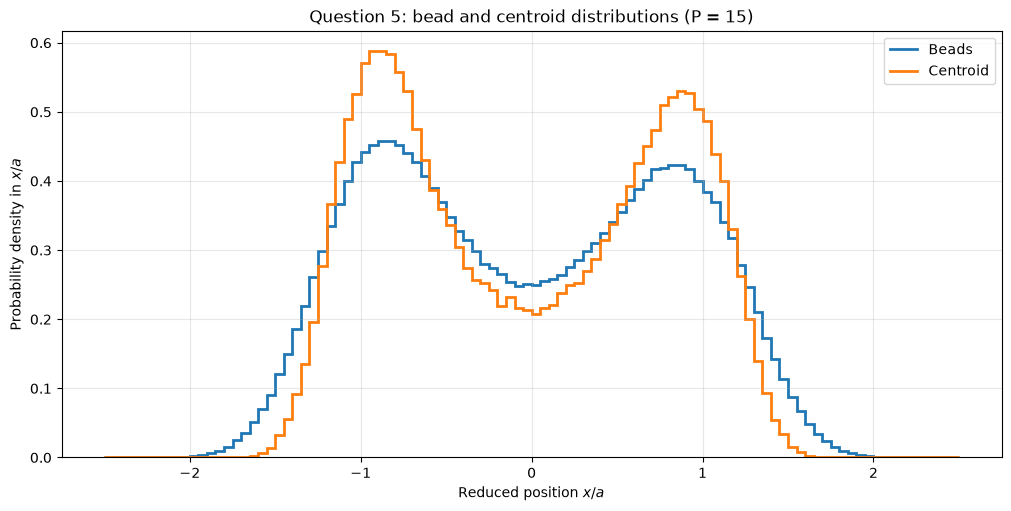

Area under bead distribution: 1.0000
Area under centroid distribution: 1.0000


In [12]:
import matplotlib.pyplot as plt

# rho and rho_centroid are already histograms: plot their values with stairs.
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.stairs(rho, edges, label="Beads", color="tab:blue", linewidth=2)
ax.stairs(rho_centroid, edges, label="Centroid", color="tab:orange", linewidth=2)
ax.set_xlabel(r"Reduced position $x/a$")
ax.set_ylabel(r"Probability density in $x/a$")
ax.set_title(f"Question 5: bead and centroid distributions (P = {params.P})")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Each area should be 1. The histogram heights themselves need not sum to 1.
widths = np.diff(edges)
print(f"Area under bead distribution: {np.sum(rho * widths):.4f}")
print(f"Area under centroid distribution: {np.sum(rho_centroid * widths):.4f}")


### Question 6

Effective barrier height: 0.6237 V0


C:\Users\Jules\AppData\Local\Temp\ipykernel_8104\2199994828.py:1: RuntimeWarning: divide by zero encountered in log
  effective_barrier = - const.k * params.T * np.log(rho_centroid / rho_centroid.max())


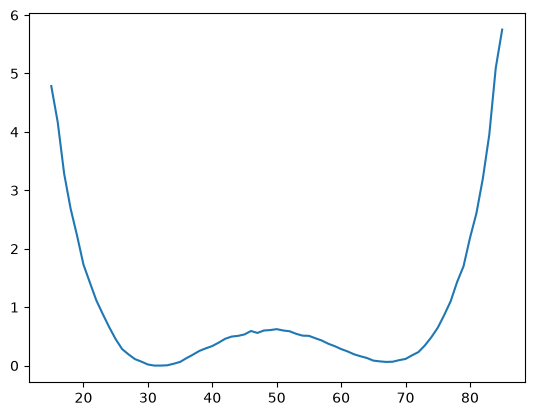

In [13]:
effective_barrier = - const.k * params.T * np.log(rho_centroid / rho_centroid.max())
plt.plot(effective_barrier / params.V0, color='tab:blue', label='Effective Barrier')
print(f"Effective barrier height: {effective_barrier[len(effective_barrier) // 2] / params.V0:.4f} V0")

# Run simulation

In [79]:
M_conf, success_list, centroid_positions, mean_energies, params, *_ = run_simulation(100000, 15, C=0.3, a_corr=0.3)

# Result analysis

In [ ]:
# Success rate calculation (should be between 40% and 50%, if not change dx)
success_rate = np.mean(success_list) * 100
print(f"Success rate: {success_rate:.2f}%")
P = params.P
a = params.a
V0 = params.V0
N = params.N

# Mean energy calculation
print(f"Mean energy: {np.mean(mean_energies) / const.e:.4e} eV")
print(f"Variance of energy: {np.var(mean_energies) / (const.e**2):.4e} eV^2")
mean_energy_prod = np.mean(mean_energies[int(np.ceil(N/2)):])  # Mean energy after equilibration (discard first half of the simulation)

# Centroid distribution calculation

print(f"Mean centroid position: {np.mean(centroid_positions):.4e} m")
print(f"Mean controid position (reduced units): {np.mean(centroid_positions) / a:.4e} a")
print(f"Variance of centroid position: {np.var(centroid_positions):.4e} m^2")

# Plots
import matplotlib.pyplot as plt

## Plot energy evolution
plt.figure(figsize=(12, 6))
plt.plot(mean_energies / const.e)
plt.title('Potential energy of the particle evolution (eV)')

## Plot energy evolution with moving average
window_size = max(1, int(N * 0.05))
energies_eV = mean_energies / const.e
kernel = np.ones(window_size) / window_size
moving_avg = np.convolve(energies_eV, kernel, mode='valid')
x_original = np.arange(N)  # Replace with actual time/step array if available
offset = (window_size - 1) / 2.0
x_moving_avg = x_original[:len(moving_avg)] + offset
plt.figure(figsize=(12, 6))
plt.plot(x_original, energies_eV, alpha=0.4, label='Original Data')
plt.plot(x_moving_avg, moving_avg, color='red', linewidth=2, label=f'Moving Avg (w={window_size})')
plt.title(f'Potential Energy Evolution (eV) - Moving Average (window size = {window_size})')
plt.xlabel('Step / Time')
plt.ylabel('Energy (eV)')
plt.legend()
plt.grid(True)
plt.show()

## Plot centroid (reduced positions)
plt.figure(figsize=(12, 6))
plt.plot(centroid_positions/a)
plt.title('Centroid position evolution (reduced units)')

# Plot distribution of centroid positions (reduced position)
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.hist(centroid_positions / a, bins=100, density=True, alpha=0.97, color='tab:blue', label='Centroid Distribution')
ax1.set_xlabel('Reduced Position')
ax1.set_ylabel('Probability Density (Histogram)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
x = np.linspace(-1.5, 1.5, 1000)
y = (x**2 - 1)**2

ax2.plot(x, y, color='red', label='Double well potential')
ax2.plot(x, mean_energy_prod / V0 * np.ones_like(x), color='green', linestyle='--', label='Mean Potential Energy')
ax2.set_ylabel('Potential Energy (Red Curve)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

plt.title('Distribution of centroid positions (reduced units)')
plt.show()




Success rate: 80.57%
Mean energy: 2.1216e-02 eV
Variance of energy: 9.8338e-05 eV^2
Mean centroid position: -1.5212e-11 m
Mean controid position (reduced units): -3.8029e-01 a
Variance of centroid position: 6.6778e-22 m^2


# Run simulation for N increasing (see when centroid stabilizes on 0)

In [ ]:
step = 500
N_list = np.arange(1, 50000, step, dtype=int)  # List of number of sweeps to test
centroid_list = []
centroid_var = []
energy_var = []
for N_sweep in N_list:
    M_conf, success_list, centroid_positions, mean_energies, params, *_ = run_simulation(N_sweep, 1, C=0.3, a_corr=0.3)
    centroid_list.append(np.mean(centroid_positions[int(np.ceil(params.N/20)):]))  # Mean centroid position after equilibration (discard first half of the simulation)
    centroid_var.append(np.var(centroid_positions[int(np.ceil(params.N/20)):]))  # Variance of centroid position after equilibration (discard first half of the simulation)
    energy_var.append(np.var(mean_energies[int(np.ceil(params.N/20)):]))  # Variance of mean energies after equilibration (discard first half of the simulation)
    success_rate = np.mean(success_list) * 100
    print(f"Success rate for N_sweep={N_sweep}: {success_rate:.2f}%")
centroid_list = np.array(centroid_list)
centroid_var = np.array(centroid_var)
energy_var = np.array(energy_var)

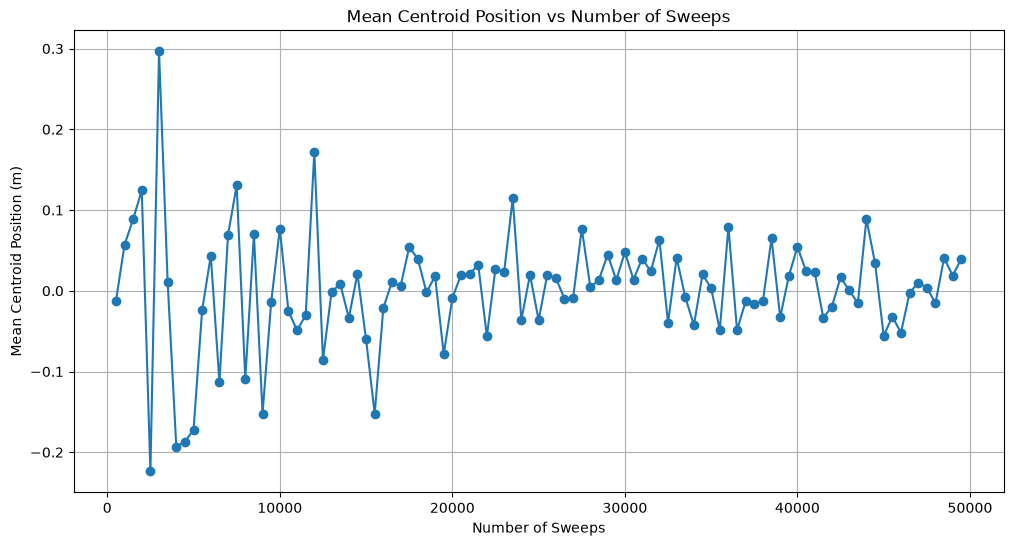

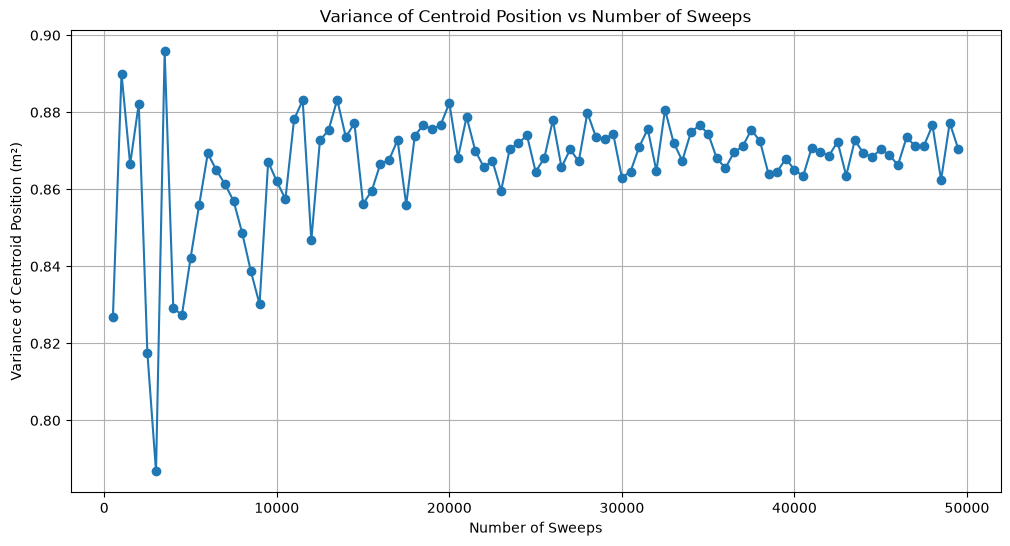

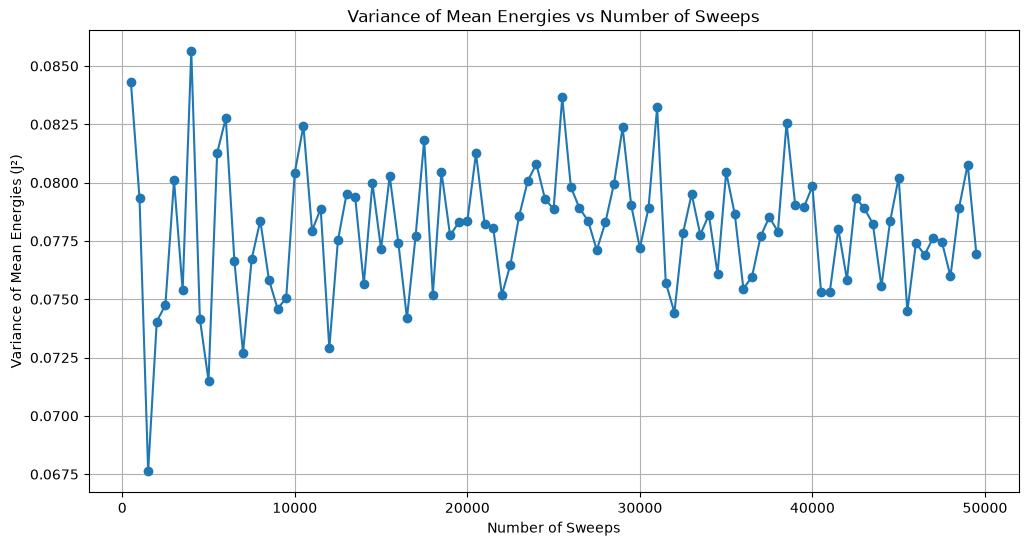

In [53]:
window_size = int(step*0.05)
plt.figure(figsize=(12, 6))
plt.plot(N_list, centroid_list / params.a, marker='o')
#plt.plot(N_list, uniform_filter1d(centroid_list, size=10, mode="nearest"), label='Filtered')
plt.title('Mean Centroid Position vs Number of Sweeps')
plt.xlabel('Number of Sweeps')
plt.ylabel('Mean Centroid Position (m)')
plt.grid(True)
plt.show()


plt.figure(figsize=(12, 6))
plt.plot(N_list, centroid_var / params.a**2, marker='o')
#plt.plot(N_list, uniform_filter1d(centroid_var, size=10, mode="nearest"), label='Filtered')
plt.title('Variance of Centroid Position vs Number of Sweeps')
plt.xlabel('Number of Sweeps')
plt.ylabel('Variance of Centroid Position (m²)')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(N_list, energy_var / params.V0**2, marker='o')
#plt.plot(N_list, uniform_filter1d(energy_var, size=10, mode="nearest"), label='Filtered')
plt.title('Variance of Mean Energies vs Number of Sweeps')
plt.xlabel('Number of Sweeps')
plt.ylabel('Variance of Mean Energies (J²)')
plt.grid(True)
plt.show()


In [ ]:
un1_un0 = []
for i in range(1, len(centroid_list)):
    un1_un0.append(centroid_list[i] - centroid_list[i-1])

un1_un0 = np.array(un1_un0)
plt.plot(un1_un0)

array([            nan,  2.80078561e-12,  1.27926540e-12,  1.42505672e-12,
       -1.39301417e-11,  2.08118985e-11, -1.14128302e-11, -8.16255746e-12,
        2.41012047e-13,  5.90455249e-13,  5.94143516e-12,  2.68432747e-12,
       -6.25455709e-12,  7.28497958e-12,  2.45632650e-12, -9.60611804e-12,
        7.18030349e-12, -8.88198434e-12,  5.52470172e-12,  3.62430676e-12,
       -4.07184572e-12, -9.57940602e-13,  7.52079851e-13,  8.06487011e-12,
       -1.02789072e-11,  3.37161663e-12,  3.95968490e-13, -1.68354906e-12,
        2.18983150e-12, -3.26022937e-12, -3.68309173e-12,  5.24430809e-12,
        1.29003468e-12, -2.07410867e-13,  1.93890506e-12, -5.98679502e-13,
       -1.64757630e-12,  7.91993735e-13, -3.85389606e-12,  2.77321557e-12,
        1.14821134e-12,  4.04716832e-14,  4.66530969e-13, -3.54171845e-12,
        3.35083631e-12, -1.79447906e-13,  3.66011898e-12, -6.02945851e-12,
        2.24700102e-12, -2.25808115e-12,  2.25056199e-12, -1.63638922e-13,
       -1.02240021e-12,  

# Run simulation with P increasing

In [ ]:
P_list = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14, 16, 18, 20, 24, 28, 32]  # List of number of beads to test
plt.figure(figsize=(12, 6))
plt.title('Mean energy vs number of beads')
plt.xlabel('Number of beads (P)')
plt.ylabel('Mean energy (eV)')
for i in range(3):  # Run the simulation three times to check for consistency
    energy_list = []
    for P in P_list:
        M_conf, success_list, centroid_positions, mean_energies, params, *_ = run_simulation(30000, P)
        success_rate = np.mean(success_list) * 100
        # print(f"Success rate for P={P}: {success_rate:.2f}%")
        # print(f"Mean energy for P={P}: {np.mean(mean_energies[3*P:]) / const.e:.4e} eV")
        # print(f"Mean centroid position for P={P}: {np.mean(centroid_positions) / params.a:.4e} a")
        # print("-" * 40)
        energy_list.append(np.mean(mean_energies[3*P:]))  # Mean energy after equilibration (to be fined-tuned)


    # Plot mean energy vs number of beads
    plt.plot(P_list, np.array(energy_list) / const.e, marker='o', label=f'Run {i+1}')
plt.show()
    


We choose P=15 as a compromise between accuracy and computational cost. Beyond this value, the estimated mean potential energy shows no clear systematic change within the observed statistical fluctuations.